Largeur : 320
Hauteur : 200
Bits par pixel : 8
Compression : 1


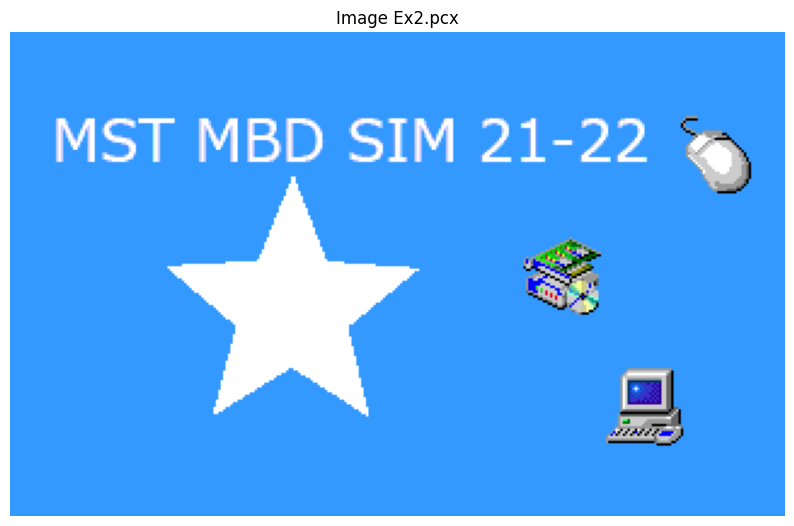

In [1]:

import struct
import numpy as np
import matplotlib.pyplot as plt

# Ouvrir le fichier en mode binaire
with open("Ex2.pcx", "rb") as f:
    data = f.read()

# 1. Lire le header
header = data[:128]

fabricant = header[0]
version = header[1]
compression = header[2]
bits = header[3]

xmin, ymin, xmax, ymax = struct.unpack_from(
    "<4H", header, 4
)

largeur = xmax - xmin + 1
hauteur = ymax - ymin + 1

plans = header[65]
bytes_per_line = struct.unpack_from(
    "<H", header, 66
)[0]

print("Largeur :", largeur)
print("Hauteur :", hauteur)
print("Bits par pixel :", bits)
print("Compression :", compression)

if fabricant != 10 or bits != 8 or plans != 1:
    raise ValueError("Format PCX non pris en charge")

if compression not in (0, 1):
    raise ValueError("Compression inconnue")

# 2. Lire la palette RGB (256 couleurs)
if len(data) < 897 or data[-769] != 12:
    raise ValueError("Palette PCX absente")

palette = np.frombuffer(
    data[-768:], dtype=np.uint8
).reshape(256, 3)

# 3. Recuperer les donnees image
raster = data[128:-769]

# 4. Decompression RLE
pixels = []
i = 0
total = hauteur * bytes_per_line

while len(pixels) < total:
    if i >= len(raster):
        raise ValueError("Raster incomplet")

    valeur = raster[i]
    i += 1

    if compression == 1 and valeur >= 192:
        repetition = valeur - 192

        if i >= len(raster):
            raise ValueError("RLE incomplet")

        couleur = raster[i]
        i += 1

        pixels.extend([couleur] * repetition)
    else:
        pixels.append(valeur)

if len(pixels) != total:
    raise ValueError("Taille de raster incorrecte")

# 5. Construire l'image
indices = np.array(
    pixels, dtype=np.uint8
).reshape(hauteur, bytes_per_line)

indices = indices[:, :largeur]

# 6. Convertir les indices en RGB
image = palette[indices]

# 7. Afficher l'image
plt.figure(figsize=(10, 7))
plt.imshow(image)
plt.title("Image Ex2.pcx")
plt.axis("off")
plt.show()
